# E-commerce 360 | Evolución del negocio

## Pregunta de negocio

¿Cómo evolucionan las órdenes, el valor vendido, el flete y la satisfacción en el tiempo?

Para responderla vamos a trabajar con una vista a nivel de orden y luego resumir los resultados por mes.


## 0. Preparación del entorno

Primero cargamos las librerías que vamos a usar. Si alguna no está instalada, el notebook la instala antes de continuar. También evitamos la notación científica para que los montos sean más fáciles de leer.


In [1]:
paquetes <- c(
  "readr", "dplyr", "tidyr", "stringr",
  "lubridate", "ggplot2", "purrr", "scales"
)

por_instalar <- paquetes[
  !vapply(paquetes, requireNamespace, logical(1), quietly = TRUE)
]

if (length(por_instalar) > 0) {
  install.packages(por_instalar, repos = "https://cloud.r-project.org")
}

invisible(lapply(paquetes, library, character.only = TRUE))

options(scipen = 999)


Attaching package: 'dplyr'


The following objects are masked from 'package:stats':

    filter, lag


The following objects are masked from 'package:base':

    intersect, setdiff, setequal, union



Attaching package: 'lubridate'


The following objects are masked from 'package:base':

    date, intersect, setdiff, union



Attaching package: 'scales'


The following object is masked from 'package:purrr':

    discard


The following object is masked from 'package:readr':

    col_factor




## 1. Carga de datos

Para esta pregunta usamos tres tablas de Olist:

- `orders`: fecha y estado de cada orden.
- `items`: precio y flete de los productos de cada orden.
- `reviews`: calificación dejada por el cliente.

Por ahora solo cargamos los archivos, sin hacer transformaciones.


In [2]:
ruta_datos <- "../data/olist"

orders <- read_csv(
  file.path(ruta_datos, "olist_orders_dataset.csv"),
  show_col_types = FALSE
)

items <- read_csv(
  file.path(ruta_datos, "olist_order_items_dataset.csv"),
  show_col_types = FALSE
)

reviews <- read_csv(
  file.path(ruta_datos, "olist_order_reviews_dataset.csv"),
  show_col_types = FALSE
)

## 2. Revisión inicial de los datos

Antes de unir las tablas revisamos su tamaño, la presencia de valores nulos y la cantidad de órdenes únicas. Esto nos ayuda a entender la granularidad de cada fuente y a definir cómo deben hacerse las uniones.


In [19]:
# Dimensiones de las tablas
dim(orders)
dim(items)
dim(reviews)

[1] 99441     8

[1] 112650      7

[1] 99224     7

### 2.2 Nulos y granularidad

Revisamos los valores nulos de las variables principales y cuántas órdenes únicas hay en cada tabla. Esto nos permite identificar cuáles tienen más de una fila por `order_id`.


In [4]:
tibble(
  variable = c(
    "order_purchase_timestamp",
    "price",
    "freight_value",
    "review_score"
  ),
  nulos = c(
    sum(is.na(orders$order_purchase_timestamp)),
    sum(is.na(items$price)),
    sum(is.na(items$freight_value)),
    sum(is.na(reviews$review_score))
  )
)

tibble(
  tabla = c("orders", "items", "reviews"),
  filas = c(nrow(orders), nrow(items), nrow(reviews)),
  ordenes_unicas = c(
    n_distinct(orders$order_id),
    n_distinct(items$order_id),
    n_distinct(reviews$order_id)
  )
)

variable,nulos
<chr>,<int>
order_purchase_timestamp,0
price,0
freight_value,0
review_score,0


tabla,filas,ordenes_unicas
<chr>,<int>,<int>
orders,99441,99441
items,112650,98666
reviews,99224,98673


## 3. Preparación a nivel de orden

`items` y `reviews` pueden tener más de una fila para una misma orden. Antes de hacer los joins, resumimos ambas tablas para mantener una sola fila por `order_id` y evitar duplicar montos o darle más peso a una orden.


In [5]:
items_orden <- items %>%
  group_by(order_id) %>%
  summarise(
    valor_vendido = sum(price),
    flete = sum(freight_value),
    n_items = n(),
    .groups = "drop"
  )

### 3.1 Reseñas por orden

Cuando una orden tiene más de una reseña usamos el promedio de `review_score`. Así obtenemos una medida de satisfacción por orden y mantenemos la misma granularidad que la tabla principal.


In [6]:
reviews_orden <- reviews %>%
  group_by(order_id) %>%
  summarise(
    satisfaccion = mean(review_score),
    n_reviews = n(),
    .groups = "drop"
  )

## 4. Construcción de la vista 360

Tomamos `orders` como tabla base y agregamos la información resumida de ítems y reseñas. El objetivo es tener una tabla analítica donde cada fila siga representando una orden.


In [7]:
vista_orden <- orders %>%
  left_join(items_orden, by = "order_id") %>%
  left_join(reviews_orden, by = "order_id")

### 4.1 Validación de la vista

Después de los joins comprobamos que la cantidad de filas siga siendo igual a la cantidad de órdenes únicas. También contamos las órdenes que no tienen información de ítems o reseñas.


In [8]:
vista_orden %>%
  summarise(
    filas = n(),
    ordenes_unicas = n_distinct(order_id),
    sin_items = sum(is.na(valor_vendido)),
    sin_review = sum(is.na(satisfaccion))
  )

filas,ordenes_unicas,sin_items,sin_review
<int>,<int>,<int>,<int>
99441,99441,775,768


## 5. Vista para el análisis temporal

Para comparar meses usamos solo órdenes con estado `delivered`. En la exploración previa vimos que 2016 tiene muy pocos registros y que los datos comparables llegan hasta agosto de 2018, por eso usamos el período de enero de 2017 a agosto de 2018.

Además, creamos la variable `mes` a partir de la fecha de compra.


In [9]:
vista_temporal <- vista_orden %>%
  filter(
    order_status == "delivered",
    order_purchase_timestamp >= ymd("2017-01-01"),
    order_purchase_timestamp < ymd("2018-09-01")
  ) %>%
  mutate(
    mes = floor_date(order_purchase_timestamp, "month")
  )

## 6. Resumen mensual

Agrupamos la vista por mes para obtener las cuatro métricas principales de la pregunta de negocio: número de órdenes, valor vendido, flete y satisfacción promedio.


In [10]:
resumen_mensual <- vista_temporal %>%
  group_by(mes) %>%
  summarise(
    ordenes = n(),
    valor_vendido = sum(valor_vendido, na.rm = TRUE),
    flete_total = sum(flete, na.rm = TRUE),
    satisfaccion_promedio = mean(satisfaccion, na.rm = TRUE),
    ordenes_con_review = sum(!is.na(satisfaccion)),
    .groups = "drop"
  )

resumen_mensual

mes,ordenes,valor_vendido,flete_total,satisfaccion_promedio,ordenes_con_review
<dttm>,<int>,<dbl>,<dbl>,<dbl>,<int>
2017-01-01,750,111798.4,15684.01,4.199055,741
2017-02-01,1653,234223.4,37015.92,4.202678,1643
2017-03-01,2546,359198.8,55132.10,4.187376,2527
2017-04-01,2303,340669.7,50142.72,4.137555,2290
2017-05-01,3546,489338.2,77513.15,4.238488,3518
2017-06-01,3135,421923.4,68127.00,4.222919,3111
2017-07-01,3872,481604.5,84694.56,4.258416,3842
2017-08-01,4193,554699.7,91132.66,4.311525,4165
2017-09-01,4150,607399.7,93677.82,4.267484,4118


### 6.1 Cobertura de satisfacción

No todas las órdenes tienen reseña. Calculamos qué porcentaje de órdenes de cada mes sí tiene `review_score` para saber qué tan representativo es el promedio de satisfacción.


In [11]:
resumen_mensual <- resumen_mensual %>%
  mutate(
    cobertura_review = 100 * ordenes_con_review / ordenes
  )

## 7. Evolución de los indicadores

Para contar la evolución del negocio agrupamos en una sola vista las métricas que siguen un patrón parecido: órdenes, valor vendido y flete total. La satisfacción se muestra aparte porque tiene otra escala y un comportamiento distinto.


### 7.1 Actividad mensual

Comparamos órdenes, valor vendido y flete total en tres paneles con el mismo eje de tiempo. Cada panel usa su propia escala, así podemos comparar la forma de las tendencias sin mezclar unidades distintas.


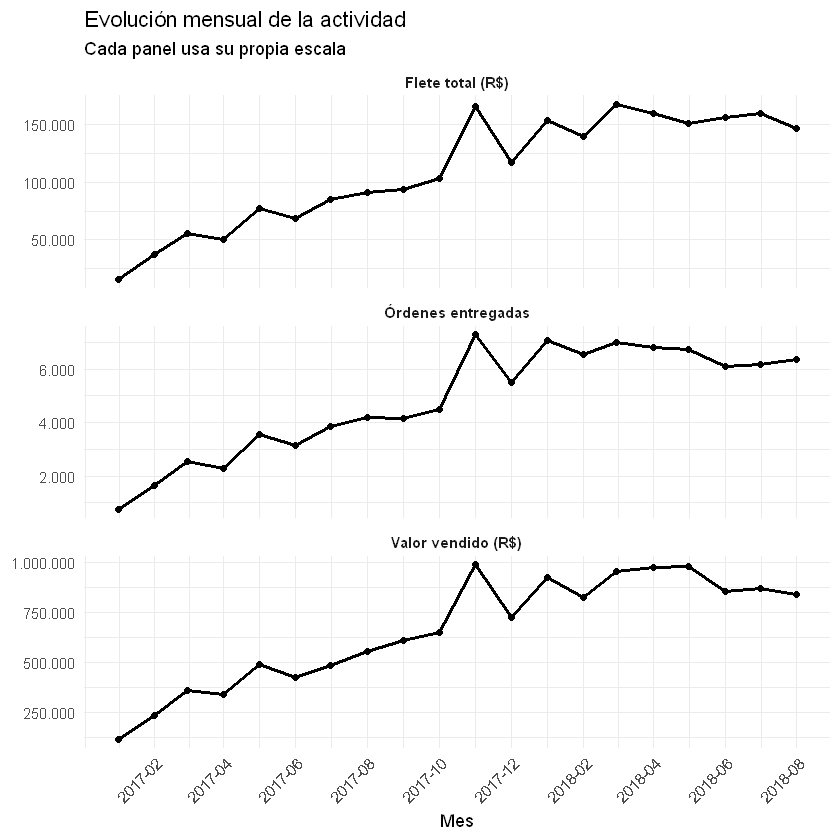

In [12]:
actividad_mensual <- resumen_mensual %>%
  select(mes, ordenes, valor_vendido, flete_total) %>%
  pivot_longer(
    cols = -mes,
    names_to = "indicador",
    values_to = "valor"
  ) %>%
  mutate(
    indicador = recode(
      indicador,
      ordenes = "Órdenes entregadas",
      valor_vendido = "Valor vendido (R$)",
      flete_total = "Flete total (R$)"
    )
  )

ggplot(actividad_mensual, aes(x = mes, y = valor)) +
  geom_line(linewidth = 0.9) +
  geom_point(size = 1.6) +
  facet_wrap(
    ~ indicador,
    ncol = 1,
    scales = "free_y"
  ) +
  scale_x_date(
    date_breaks = "2 months",
    date_labels = "%Y-%m"
  ) +
  scale_y_continuous(
    labels = scales::label_number(
      big.mark = ".",
      decimal.mark = ","
    )
  ) +
  labs(
    title = "Evolución mensual de la actividad",
    subtitle = "Cada panel usa su propia escala",
    x = "Mes",
    y = NULL
  ) +
  theme_minimal() +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    strip.text = element_text(face = "bold")
  )


### 7.2 Satisfacción

La satisfacción se analiza por separado usando el `review_score` promedio de las órdenes que tienen reseña. Esto permite ver si la experiencia del cliente cambia mientras aumenta la actividad.


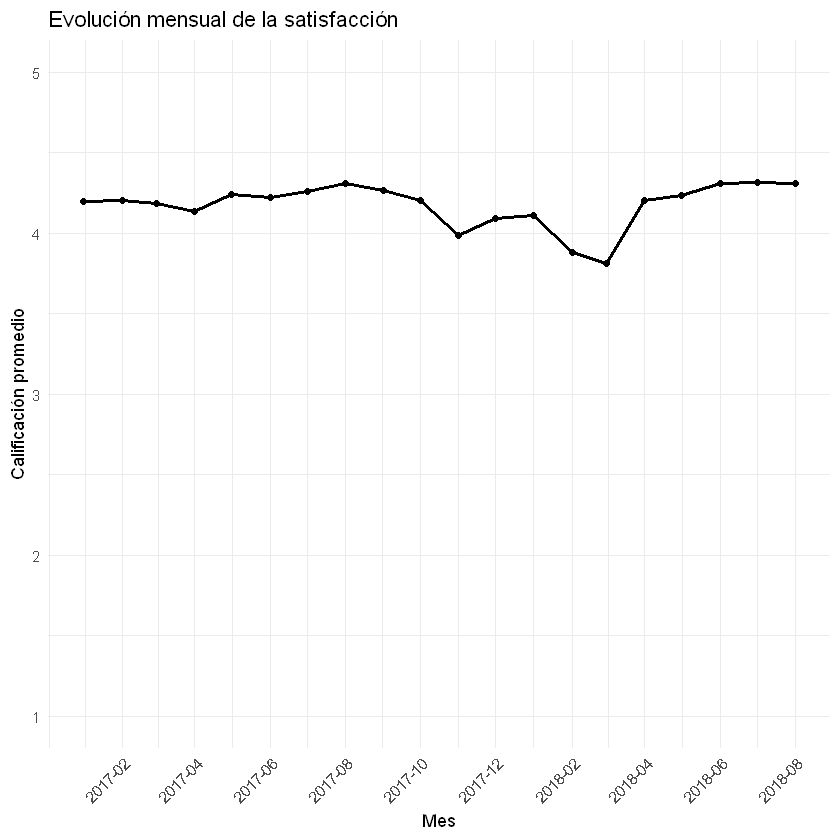

In [13]:
ggplot(resumen_mensual, aes(x = mes, y = satisfaccion_promedio)) +
  geom_line(linewidth = 1) +
  geom_point() +
  labs(
    title = "Evolución mensual de la satisfacción",
    x = "Mes",
    y = "Calificación promedio"
  ) +
  scale_x_date(
    date_breaks = "2 months",
    date_labels = "%Y-%m"
  ) +
  scale_y_continuous(
    limits = c(1, 5),
    breaks = 1:5
  ) +
  theme_minimal() +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1)
  )


### 7.3 Comparación interanual

Como 2018 solo tiene datos comparables hasta agosto, comparamos enero-agosto de 2017 contra enero-agosto de 2018. Así evitamos usar períodos de distinta duración.


In [14]:
comparacion_anual <- vista_temporal %>%
  filter(month(order_purchase_timestamp) <= 8) %>%
  mutate(anio = year(order_purchase_timestamp)) %>%
  group_by(anio) %>%
  summarise(
    ordenes = n(),
    valor_vendido = sum(valor_vendido, na.rm = TRUE),
    flete_total = sum(flete, na.rm = TRUE),
    satisfaccion_promedio = mean(satisfaccion, na.rm = TRUE),
    ordenes_con_review = sum(!is.na(satisfaccion)),
    .groups = "drop"
  )

comparacion_anual


anio,ordenes,valor_vendido,flete_total,satisfaccion_promedio,ordenes_con_review
<dbl>,<int>,<dbl>,<dbl>,<dbl>,<int>
2017,21998,2993456,479442.1,4.233175,21837
2018,52783,7218125,1233459.6,4.142036,52468


### 7.4 Variación interanual

A partir de la tabla anterior medimos cuánto cambiaron las órdenes, el valor vendido y el flete. Para satisfacción usamos la diferencia en puntos de calificación.


In [15]:
comparacion_anual %>%
  arrange(anio) %>%
  mutate(
    variacion_ordenes_pct = 100 * (ordenes / lag(ordenes) - 1),
    variacion_valor_pct = 100 * (valor_vendido / lag(valor_vendido) - 1),
    variacion_flete_pct = 100 * (flete_total / lag(flete_total) - 1),
    variacion_satisfaccion = satisfaccion_promedio - lag(satisfaccion_promedio)
  )


anio,ordenes,valor_vendido,flete_total,satisfaccion_promedio,ordenes_con_review,variacion_ordenes_pct,variacion_valor_pct,variacion_flete_pct,variacion_satisfaccion
<dbl>,<int>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
2017,21998,2993456,479442.1,4.233175,21837,NA,NA,NA,NA
2018,52783,7218125,1233459.6,4.142036,52468,139.9445,141.1301,157.2698,-0.0911388


### 7.5 Métricas por orden

Los totales pueden crecer solo porque hay más órdenes. Por eso calculamos el valor vendido promedio y el flete promedio por orden.


In [16]:
resumen_mensual <- resumen_mensual %>%
  mutate(
    valor_promedio_orden = valor_vendido / ordenes,
    flete_promedio_orden = flete_total / ordenes
  )

resumen_mensual %>%
  select(
    mes,
    valor_promedio_orden,
    flete_promedio_orden
  )


mes,valor_promedio_orden,flete_promedio_orden
<dttm>,<dbl>,<dbl>
2017-01-01,149.0645,20.91201
2017-02-01,141.6959,22.39318
2017-03-01,141.0836,21.65440
2017-04-01,147.9243,21.77278
2017-05-01,137.9973,21.85932
2017-06-01,134.5848,21.73110
2017-07-01,124.3813,21.87360
2017-08-01,132.2918,21.73448
2017-09-01,146.3614,22.57297


### 7.6 Comparación de métricas relativas

Comparamos enero-agosto de ambos años para ver si el crecimiento también aparece en el valor y el flete promedio de cada orden.


In [17]:
comparacion_relativa <- vista_temporal %>%
  filter(month(order_purchase_timestamp) <= 8) %>%
  mutate(anio = year(order_purchase_timestamp)) %>%
  group_by(anio) %>%
  summarise(
    valor_promedio_orden = mean(valor_vendido, na.rm = TRUE),
    flete_promedio_orden = mean(flete, na.rm = TRUE),
    .groups = "drop"
  )

comparacion_relativa


anio,valor_promedio_orden,flete_promedio_orden
<dbl>,<dbl>,<dbl>
2017,136.0786,21.7948
2018,136.7509,23.3685


### 7.7 Flete promedio por orden

El valor promedio por orden cambia poco entre ambos años. En cambio, el flete promedio sí muestra más variación, por eso lo revisamos también a lo largo del tiempo.


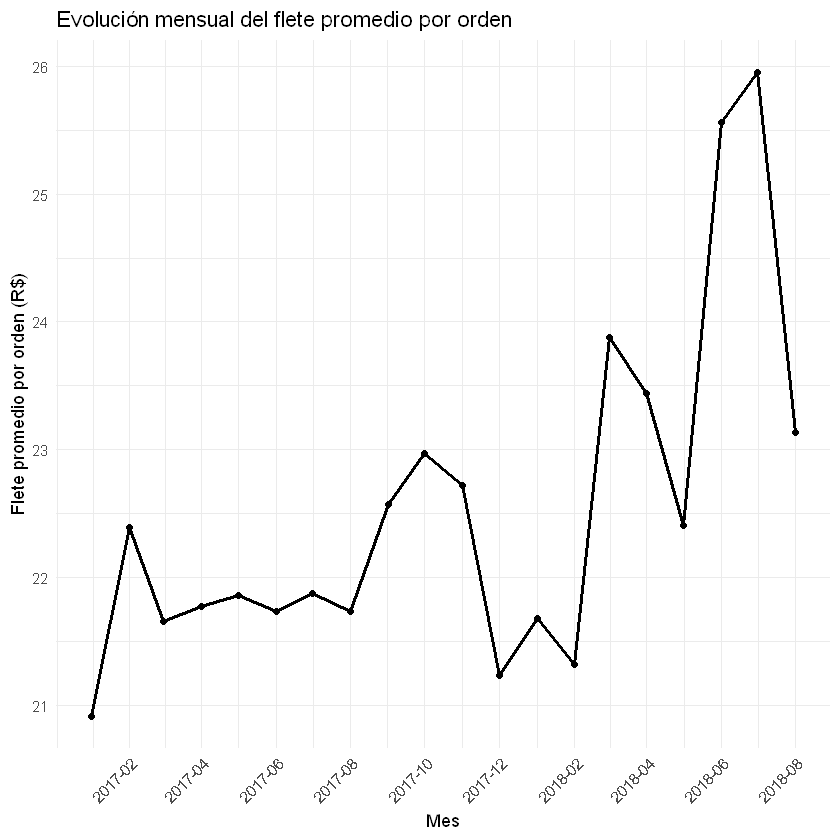

In [18]:
ggplot(resumen_mensual, aes(x = mes, y = flete_promedio_orden)) +
  geom_line(linewidth = 1) +
  geom_point() +
  labs(
    title = "Evolución mensual del flete promedio por orden",
    x = "Mes",
    y = "Flete promedio por orden (R$)"
  ) +
  scale_x_date(
    date_breaks = "2 months",
    date_labels = "%Y-%m"
  ) +
  theme_minimal() +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1)
  )


## Draft de Conclusión
La actividad crece con fuerza durante 2017 y se mantiene en niveles altos durante 2018. Órdenes, valor vendido y flete total siguen una evolución bastante parecida.

Al comparar enero-agosto de ambos años, el valor promedio por orden cambia poco. Esto indica que gran parte del crecimiento del valor vendido viene de tener más órdenes.

El flete promedio por orden sí es mayor en 2018. La satisfacción presenta una caída entre finales de 2017 y los primeros meses de 2018, pero luego se recupera.
